# Training-Set Size Ablation — de_dust2

Trains all five models (LightGBM, DeepSets, SetTransformer, GCNSimple, GAT) on de_dust2
with an **incrementally growing training set** across 10 steps (~35 matches per step).
Steps 0–5 grow through Season 1; steps 6–9 add Season 2 training tournaments on top.

**Val and test sets are fixed throughout** (identical to the main training notebook).  
Models are re-initialised from scratch at each step — no checkpoint reuse.  
Only test-set LL and ECE are retained; model weights are discarded after each step.

---
**Steps:**

| Step | Added group | Cumul. matches |
|------|-------------|----------------|
| 0 | S1: BLAST Bounty · IEM Katowice | 34 |
| 1 | S1: + PGL Cluj · EPL S21 S1 · BLAST Lisbon | 79 |
| 2 | S1: + IEM Melbourne · EPL S21 S2 · YaLLa · Asian | 115 |
| 3 | S1: + MESA · PGL Astana · PGL Bucharest | 160 |
| 4 | S1: + IEM Dallas · CCT · FISSURE1 | 194 |
| 5 | S1: complete (+ Rivals1 · BLAST Major) | 237 |
| 6 | S2: + BLAST Bounty S2 · IEM Cologne | 265 |
| 7 | S2: + EPL S1 · BLAST London | 287 |
| 8 | S2: + EWC · FISSURE2 · SS Fall · CS Asia | 328 |
| 9 | S2: complete (+ Chengdu · PGL Buch · Thunderpick · Rivals2) | 359 |

Sections: **0 Setup** | **1 Load data** | **2 Split** | **3 Models** | **4 Helpers** | **5 Ablation loop** | **6 Results**

## 0. Imports & Config

In [1]:
!pip install torch_geometric -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.7/63.7 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 34.0 MB/s eta 0:00:00


In [2]:
import os, json, random, warnings, tempfile
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adam
from torch_geometric.loader import DataLoader as PyGLoader
from torch_geometric.nn import GCNConv, GATConv, global_mean_pool, BatchNorm
from torch_geometric.utils import dropout_edge
import lightgbm as lgb
from sklearn.metrics import log_loss
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

from google.colab import drive
drive.mount('/content/drive')

import sys
BASE = Path('/content/drive/MyDrive/magisterka')
sys.path.insert(0, str(BASE))

from dataset import (
    load_processed_matches, flatten_to_states,
    VectorDataset, SetDataset, SetNormaliser,
    GraphDataset, build_datasets,
)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')

Mounted at /content/drive
Device: cuda


In [6]:
# ── Map config ────────────────────────────────────────────────────────────
MAP_NAME = 'dust2'

PROCESSED_DIR = BASE / 'data' / MAP_NAME
S1_DIR = PROCESSED_DIR / 'season1'
S2_DIR = PROCESSED_DIR / 'season2'

TMP_CKPT_DIR = Path(tempfile.mkdtemp())

print(f'Map:             de_{MAP_NAME}')
print(f'Season 1 exists: {S1_DIR.exists()}')
print(f'Season 2 exists: {S2_DIR.exists()}')
print(f'Temp ckpt dir:   {TMP_CKPT_DIR}')

# ── Shared hyperparameters (match main training notebook exactly) ─────────
CFG = dict(
    hidden      = 128,
    batch_size  = 32,
    lr          = 1e-3,
    weight_decay= 1e-4,
    grad_clip   = 1.0,
    epochs      = 100,
    patience    = 10,
    ece_bins    = 10,
)

# ── Graph-model overrides (identical to main notebook) ───────────────────
GRAPH_CFG = dict(
    hidden        = 32,
    dropout_gcn   = 0.5,
    dropout_gat   = 0.3,
    drop_edge_p   = 0.5,
    weight_decay  = 1e-3,
    patience      = 5,
    lr_warmup_gat = 1e-4,
    warmup_epochs = 5,
)

print(f'CFG:       {CFG}')
print(f'GRAPH_CFG: {GRAPH_CFG}')

Map:             de_dust2
Season 1 exists: True
Season 2 exists: True
Temp ckpt dir:   /tmp/tmp4yin2p9a
CFG:       {'hidden': 128, 'batch_size': 32, 'lr': 0.001, 'weight_decay': 0.0001, 'grad_clip': 1.0, 'epochs': 100, 'patience': 10, 'ece_bins': 10}
GRAPH_CFG: {'hidden': 32, 'dropout_gcn': 0.5, 'dropout_gat': 0.3, 'drop_edge_p': 0.5, 'weight_decay': 0.001, 'patience': 5, 'lr_warmup_gat': 0.0001, 'warmup_epochs': 5}


## 1. Load Data

Load Season 1 and Season 2 into memory once. The ablation loop subsets by tournament name — no repeated disk reads.

In [15]:
from tqdm import tqdm

def get_tournament(match_key: str) -> str:
    """Extract tournament name from a match key (filename stem)."""
    parts = match_key.split('_')
    for i in range(len(parts) - 1, 0, -1):
        if '-vs-' in parts[i]:
            return '_'.join(parts[:i])
    return parts[0]

def load_season(season_dir: Path) -> dict:
    data = {}
    if not season_dir.exists():
        print(f'  ⚠️  {season_dir} not found — skipping')
        return data
    for fname in tqdm(sorted(season_dir.glob('*.json')), desc=str(season_dir.name)):
        with open(fname) as f:
            data.update(json.load(f))
    return data

print('Loading data...')
s1_data = load_season(S1_DIR)
s2_data = load_season(S2_DIR)
print(f'Season 1: {len(s1_data):,} matches')
print(f'Season 2: {len(s2_data):,} matches')

for season_label, data in [('S1', s1_data), ('S2', s2_data)]:
    tourneys = sorted({get_tournament(k) for k in data})
    print(f'\n{season_label} tournaments ({len(tourneys)}):')
    for t in tourneys:
        n = sum(1 for k in data if get_tournament(k) == t)
        print(f'  {n:3d}  {t}')

Loading data...


season2: 100%|██████████| 167/167 [02:00<00:00,  1.39it/s]


Season 1: 237 matches
Season 2: 167 matches

S1 tournaments (33):
    6  Asian Champions League
   12  BLAST Bounty Season 1
    5  BLAST Bounty Season 1 Finals
   12  BLAST Major
    2  BLAST Major Playoffs
    7  BLAST Major Stage 1
   14  BLAST Major Stage 2
   12  BLAST Open Lisbon
    3  BLAST Open Lisbon Playoffs
    4  BLAST Rivals Season 1 Groups
    4  BLAST Rivals Season 1 Playoffs
    9  CCT Global Finals
    3  ESL Pro League Season 21 Playoffs
   14  ESL Pro League Season 21 Stage 1
   12  ESL Pro League Season 21 Stage 2
    9  FISSURE Playground 1
    2  FISSURE Playground 1 Playoffs
   11  IEM Dallas
    3  IEM Dallas Playoffs
    9  IEM Katowice
    6  IEM Katowice Play-in
    2  IEM Katowice Playoffs
    7  IEM Melbourne
    2  IEM Melbourne Playoffs
    5  MESA Nomadic Masters Groups
    3  MESA Nomadic Masters Playoffs
   13  PGL Astana
    3  PGL Astana Playoffs
   18  PGL Bucharest
    3  PGL Bucharest Playoffs
   13  PGL Cluj-Napoca
    3  PGL Cluj-Napoca Playoff

## 2. Val / Test Split & Ablation Steps

In [16]:
# ── Fixed val / test split ────────────────────────────────────────────────
VAL_TOURNAMENTS = {
    'ESL Pro League Stage 2',
    'ESL Pro League Playoffs',
    'CS Asia Championships',
    'CS Asia Championships Playoffs',
    'IEM Chengdu',
    'IEM Chengdu Playoffs',
    'PGL Masters Bucharest',
    'PGL Masters Bucharest Playoffs',
    'Thunderpick World Championship',
    'BLAST Rivals Season 2',
    'BLAST Rivals Season 2 Playoffs',
}
TEST_TOURNAMENTS = {
    'StarLadder Major Stage 1',
    'StarLadder Major Stage 2',
    'StarLadder Major Stage 3',
    'StarLadder Major Playoffs',
}

val_data  = {k: v for k, v in s2_data.items() if get_tournament(k) in VAL_TOURNAMENTS}
test_data = {k: v for k, v in s2_data.items() if get_tournament(k) in TEST_TOURNAMENTS}

# ── 10-step cumulative ablation ───────────────────────────────────────────
# Each S1_STEPS entry lists the *new* tournaments added at that step.
# Internally they are accumulated (cumulative) before being stored in ABLATION_STEPS.
# S2 steps always include the full S1 training set.

S1_STEPS = [
    # Step 0 — 34 matches
    ('S1: BLAST Bounty·IEM Katowice', [
        'BLAST Bounty Season 1', 'BLAST Bounty Season 1 Finals',
        'IEM Katowice', 'IEM Katowice Play-in', 'IEM Katowice Playoffs',
    ]),
    # Step 1 — +45 = 79 matches
    ('S1: +PGL Cluj·EPL S21 S1·BLAST Lisbon', [
        'PGL Cluj-Napoca', 'PGL Cluj-Napoca Playoffs',
        'ESL Pro League Season 21 Stage 1',
        'BLAST Open Lisbon', 'BLAST Open Lisbon Playoffs',
    ]),
    # Step 2 — +36 = 115 matches
    ('S1: +IEM Melbourne·EPL S21 S2·YaLLa·Asian', [
        'IEM Melbourne', 'IEM Melbourne Playoffs',
        'ESL Pro League Season 21 Stage 2', 'ESL Pro League Season 21 Playoffs',
        'YaLLa Compass Groups',
        'Asian Champions League',
    ]),
    # Step 3 — +45 = 160 matches
    ('S1: +MESA·PGL Astana·PGL Bucharest', [
        'MESA Nomadic Masters Groups', 'MESA Nomadic Masters Playoffs',
        'PGL Astana', 'PGL Astana Playoffs',
        'PGL Bucharest', 'PGL Bucharest Playoffs',
    ]),
    # Step 4 — +34 = 194 matches
    ('S1: +IEM Dallas·CCT·FISSURE1', [
        'IEM Dallas', 'IEM Dallas Playoffs',
        'CCT Global Finals',
        'FISSURE Playground 1', 'FISSURE Playground 1 Playoffs',
    ]),
    # Step 5 — +43 = 237 matches  (S1 complete)
    ('S1: complete (+Rivals1·BLAST Major)', [
        'BLAST Rivals Season 1 Groups', 'BLAST Rivals Season 1 Playoffs',
        'BLAST Major Stage 1', 'BLAST Major Stage 2', 'BLAST Major', 'BLAST Major Playoffs',
    ]),
]

S2_STEPS = [
    # Step 6 — +28 = 265 matches
    ('S2: BLAST Bounty·IEM Cologne', [
        'BLAST Bounty Season 2', 'BLAST Bounty Season 2 Finals',
        'IEM Cologne', 'IEM Cologne Stage 1', 'IEM Cologne Playoffs',
    ]),
    # Step 7 — +22 = 287 matches
    ('S2: +EPL S1·BLAST London', [
        'ESL Pro League Stage 1',
        'BLAST Open London', 'BLAST Open London Finals',
    ]),
    # Step 8 — +41 = 328 matches
    ('S2: +EWC·FISSURE2·SS Fall·CS Asia', [
        'Esports World Cup',
        'FISSURE Playground 2', 'FISSURE Playground 2 Playoffs',
        'StarLadder StarSeries Fall',
        'CS Asia Championships', 'CS Asia Championships Playoffs',
    ]),
    # Step 9 — +31 = 359 matches  (full training set)
    ('S2: complete (+Chengdu·PGL Buch·Thunderpick·Rivals2)', [
        'IEM Chengdu', 'IEM Chengdu Playoffs',
        'PGL Masters Bucharest', 'PGL Masters Bucharest Playoffs',
        'Thunderpick World Championship',
        'BLAST Rivals Season 2', 'BLAST Rivals Season 2 Playoffs',
    ]),
]

# ── Build ABLATION_STEPS ──────────────────────────────────────────────────
# Each entry: (step_idx, label, s1_inc, s2_inc)
# s1_inc / s2_inc are cumulative tournament name lists for that step.

_s1_cumulative, _seen_s1 = [], []
for label, batch in S1_STEPS:
    _seen_s1 = _seen_s1 + batch
    _s1_cumulative.append((label, list(_seen_s1)))

_s2_cumulative, _seen_s2 = [], []
for label, batch in S2_STEPS:
    _seen_s2 = _seen_s2 + batch
    _s2_cumulative.append((label, list(_seen_s2)))

ABLATION_STEPS = []
for i, (label, s1_inc) in enumerate(_s1_cumulative):
    ABLATION_STEPS.append((i, label, s1_inc, []))
for i, (label, s2_inc) in enumerate(_s2_cumulative, start=len(S1_STEPS)):
    ABLATION_STEPS.append((i, label, list(_seen_s1), s2_inc))

def count_rounds(d): return sum(len({r.get('roundNum') for r in v['df']}) for v in d.values())
def count_states(d): return sum(len(v['Y']) for v in d.values())

print(f'Val  : {len(val_data):4d} matches | {count_rounds(val_data):>6,} rounds')
print(f'Test : {len(test_data):4d} matches | {count_rounds(test_data):>6,} rounds')
print(f'\nAblation steps: {len(ABLATION_STEPS)}')
for step_idx, label, s1_inc, s2_inc in ABLATION_STEPS:
    n_s1 = sum(1 for k in s1_data if get_tournament(k) in set(s1_inc))
    n_s2 = sum(1 for k in s2_data if get_tournament(k) in set(s2_inc))
    print(f'  Step {step_idx}: {n_s1+n_s2:3d} matches  |  {label}')

# Sanity check
s1_unaccounted = {get_tournament(k) for k in s1_data} - set(_seen_s1)
s2_unaccounted = {get_tournament(k) for k in s2_data} - set(_seen_s2) - VAL_TOURNAMENTS - TEST_TOURNAMENTS
if s1_unaccounted: print(f'⚠️  Unaccounted S1: {s1_unaccounted}')
if s2_unaccounted: print(f'⚠️  Unaccounted S2: {s2_unaccounted}')
if not s1_unaccounted and not s2_unaccounted: print('✓  All tournaments accounted for.')

Val  :   60 matches |  1,286 rounds
Test :   31 matches |    703 rounds

Ablation steps: 10
  Step 0:  34 matches  |  S1: BLAST Bounty·IEM Katowice
  Step 1:  79 matches  |  S1: +PGL Cluj·EPL S21 S1·BLAST Lisbon
  Step 2: 115 matches  |  S1: +IEM Melbourne·EPL S21 S2·YaLLa·Asian
  Step 3: 160 matches  |  S1: +MESA·PGL Astana·PGL Bucharest
  Step 4: 194 matches  |  S1: +IEM Dallas·CCT·FISSURE1
  Step 5: 237 matches  |  S1: complete (+Rivals1·BLAST Major)
  Step 6: 265 matches  |  S2: BLAST Bounty·IEM Cologne
  Step 7: 287 matches  |  S2: +EPL S1·BLAST London
  Step 8: 328 matches  |  S2: +EWC·FISSURE2·SS Fall·CS Asia
  Step 9: 359 matches  |  S2: complete (+Chengdu·PGL Buch·Thunderpick·Rivals2)
✓  All tournaments accounted for.


## 3. Model Definitions

In [8]:
class DeepSets(nn.Module):
    """
    DeepSets (Zaheer et al., 2017).
    Hyperparameters consistent with ESTA paper:
      lr=1e-3, batch_size=32, epochs=100, early_stopping=10.
    hidden=128; dropout=0.3.
    """
    def __init__(self, in_features=32, hidden=128, dropout=0.3):
        super().__init__()
        self.phi = nn.Sequential(
            nn.Linear(in_features, hidden), nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, hidden),
        )
        self.rho = nn.Sequential(
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, x):
        return self.rho(self.phi(x).mean(dim=1))

In [9]:
class MultiheadAttentionBlock(nn.Module):
    def __init__(self, d_model, num_heads, dropout=0.1):
        super().__init__()
        self.attn  = nn.MultiheadAttention(d_model, num_heads, dropout=dropout, batch_first=True)
        self.norm1 = nn.LayerNorm(d_model)
        self.ff    = nn.Sequential(nn.Linear(d_model, d_model), nn.ReLU(),
                                   nn.Dropout(dropout), nn.Linear(d_model, d_model))
        self.norm2 = nn.LayerNorm(d_model)

    def forward(self, x):
        attn_out, _ = self.attn(x, x, x)
        x = self.norm1(x + attn_out)
        return self.norm2(x + self.ff(x))


class InducedSetAttentionBlock(nn.Module):
    def __init__(self, d_model, num_heads, num_inds=4, dropout=0.1):
        super().__init__()
        self.I    = nn.Parameter(torch.randn(1, num_inds, d_model))
        self.mab0 = MultiheadAttentionBlock(d_model, num_heads, dropout)
        self.mab1 = MultiheadAttentionBlock(d_model, num_heads, dropout)

    def forward(self, x):
        B = x.size(0)
        H = self.mab0(torch.cat([self.I.expand(B, -1, -1), x], dim=1))[:, :self.I.size(1)]
        return self.mab1(torch.cat([x, H], dim=1))[:, :x.size(1)]


class PoolingByMultiheadAttention(nn.Module):
    def __init__(self, d_model, num_heads, k=1, dropout=0.1):
        super().__init__()
        self.S   = nn.Parameter(torch.randn(1, k, d_model))
        self.mab = MultiheadAttentionBlock(d_model, num_heads, dropout)

    def forward(self, x):
        B = x.size(0)
        return self.mab(torch.cat([self.S.expand(B, -1, -1), x], dim=1))[:, :self.S.size(1)]


class SetTransformer(nn.Module):
    """
    Set Transformer (Lee et al., 2019).
    Hyperparameters consistent with ESTA paper:
      lr=1e-3, batch_size=32, epochs=100, early_stopping=10.
    num_heads=1, num_inds=4 (ESTA defaults).
    """
    def __init__(self, in_features=32, hidden=128, num_heads=1, num_inds=4, dropout=0.1):
        super().__init__()
        self.embed = nn.Linear(in_features, hidden)
        self.isab1 = InducedSetAttentionBlock(hidden, num_heads, num_inds, dropout)
        self.isab2 = InducedSetAttentionBlock(hidden, num_heads, num_inds, dropout)
        self.pma   = PoolingByMultiheadAttention(hidden, num_heads, k=1, dropout=dropout)
        self.head  = nn.Linear(hidden, 1)

    def forward(self, x):
        x = F.relu(self.embed(x))
        x = self.isab1(x)
        x = self.isab2(x)
        x = self.pma(x).squeeze(1)
        return self.head(x)

In [10]:
class GCNSimple(nn.Module):
    """
    Two-layer GCN with full edge features (distance, visibility, same_team).
    hidden=32 (GRAPH_CFG), dropout=0.5, drop_edge_p=0.5.
    """
    def __init__(self, hidden=32, num_node_features=32, dropout=0.5, drop_edge_p=0.5):
        super().__init__()
        self.drop_edge_p = drop_edge_p
        in_dim = num_node_features + 2
        self.conv1 = GCNConv(in_dim, hidden)
        self.bn1   = BatchNorm(hidden)
        self.conv2 = GCNConv(hidden, hidden)
        self.bn2   = BatchNorm(hidden)
        self.mlp   = nn.Sequential(
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, data):
        x, ei, ea, batch = data.x, data.edge_index, data.edge_attr, data.batch
        if self.training:
            ei, edge_mask = dropout_edge(ei, p=self.drop_edge_p, training=True)
            ea = ea[edge_mask]
        n   = x.size(0)
        src = ei[0]
        vis_vals  = ea[:, 1].unsqueeze(1)
        team_vals = ea[:, 2].unsqueeze(1)
        vis_agg   = torch.zeros(n, 1, device=x.device)
        team_agg  = torch.zeros(n, 1, device=x.device)
        count     = torch.zeros(n, 1, device=x.device)
        ones      = torch.ones(src.size(0), 1, device=x.device)
        vis_agg.scatter_add_(0,  src.unsqueeze(1), vis_vals)
        team_agg.scatter_add_(0, src.unsqueeze(1), team_vals)
        count.scatter_add_(0,    src.unsqueeze(1), ones)
        count = count.clamp(min=1)
        x_in  = torch.cat([x, vis_agg / count, team_agg / count], dim=1)
        ew    = ea[:, 0].clamp(max=10.0)
        x_in = F.relu(self.bn1(self.conv1(x_in, ei, ew)))
        x_in = F.relu(self.bn2(self.conv2(x_in, ei, ew)))
        return self.mlp(global_mean_pool(x_in, batch))

In [11]:
class GAT(nn.Module):
    """
    Two-layer GAT with full 3-dim edge features.
    4 heads x 8 head-dim = 32-dim output (hidden=32 via GRAPH_CFG).
    dropout=0.3, drop_edge_p=0.5. LR warmup handled in training loop.
    """
    def __init__(self, hidden=32, num_node_features=32, num_edge_features=3,
                 heads=4, dropout=0.3, drop_edge_p=0.5):
        super().__init__()
        self.drop_edge_p = drop_edge_p
        head_dim = hidden // heads
        self.conv1 = GATConv(num_node_features, head_dim, heads=heads,
                             edge_dim=num_edge_features, concat=True, dropout=dropout)
        self.bn1   = BatchNorm(hidden)
        self.conv2 = GATConv(hidden, head_dim, heads=heads,
                             edge_dim=num_edge_features, concat=True, dropout=dropout)
        self.bn2   = BatchNorm(hidden)
        self.mlp   = nn.Sequential(
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, data):
        x, ei, ea, batch = data.x, data.edge_index, data.edge_attr, data.batch
        if self.training:
            ei, edge_mask = dropout_edge(ei, p=self.drop_edge_p, training=True)
            ea = ea[edge_mask]
        x = F.relu(self.bn1(self.conv1(x, ei, ea)))
        x = F.relu(self.bn2(self.conv2(x, ei, ea)))
        return self.mlp(global_mean_pool(x, batch))

## 4. Training Helpers

In [12]:
# ── Metrics ───────────────────────────────────────────────────────────────

def compute_ece(y_true, y_prob, n_bins=10):
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece, n = 0.0, len(y_true)
    for lo, hi in zip(bins[:-1], bins[1:]):
        mask = (y_prob >= lo) & (y_prob < hi)
        if mask.sum() == 0:
            continue
        ece += mask.sum() / n * abs(y_true[mask].mean() - y_prob[mask].mean())
    return float(ece)


# ── Prediction helpers ────────────────────────────────────────────────────

@torch.no_grad()
def predict_set_model(model, batches):
    model.eval()
    probs, trues = [], []
    for xb, yb in batches:
        xb = xb.to(DEVICE)
        probs.append(torch.sigmoid(model(xb)).cpu().numpy().flatten())
        trues.append(yb.numpy().flatten())
    return np.concatenate(trues), np.concatenate(probs)


@torch.no_grad()
def predict_graph_model(model, loader):
    model.eval()
    probs, trues = [], []
    for batch in loader:
        batch = batch.to(DEVICE)
        probs.append(torch.sigmoid(model(batch)).cpu().numpy().flatten())
        trues.append(batch.y.cpu().numpy().flatten())
    return np.concatenate(trues), np.concatenate(probs)


# ── Set model training loop ───────────────────────────────────────────────

def train_set_model(model, train_ds, val_ds, ckpt_path):
    model = model.to(DEVICE)
    optim = Adam(model.parameters(), lr=CFG['lr'], weight_decay=CFG['weight_decay'])
    crit  = nn.BCEWithLogitsLoss()
    best_val, best_ep, no_improve = float('inf'), 0, 0

    for ep in range(1, CFG['epochs'] + 1):
        model.train()
        tot_loss, tot_n = 0.0, 0
        for xb, yb in train_ds.make_batches(CFG['batch_size'], shuffle=True):
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optim.zero_grad()
            loss = crit(model(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), CFG['grad_clip'])
            optim.step()
            tot_loss += loss.item() * xb.size(0)
            tot_n    += xb.size(0)
        y_true, y_prob = predict_set_model(model, val_ds.make_batches(CFG['batch_size']))
        val_ll = log_loss(y_true, y_prob)
        print(f'    Epoch {ep:3d}  train LL={tot_loss/tot_n:.4f}  val LL={val_ll:.4f}')
        if val_ll < best_val:
            best_val, best_ep, no_improve = val_ll, ep, 0
            torch.save(model.state_dict(), ckpt_path)
        else:
            no_improve += 1
            if no_improve >= CFG['patience']:
                print(f'    Early stop at epoch {ep} (best epoch {best_ep}, val LL={best_val:.4f})')
                break

    model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
    return model


# ── GCNSimple training loop ───────────────────────────────────────────────

def train_gcn_model(model, train_ds, val_ds, ckpt_path):
    model = model.to(DEVICE)
    optim = Adam(model.parameters(), lr=CFG['lr'], weight_decay=GRAPH_CFG['weight_decay'])
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optim, mode='min', factor=0.5, patience=3)
    crit  = nn.BCEWithLogitsLoss()
    train_loader = PyGLoader(train_ds, batch_size=CFG['batch_size'], shuffle=True)
    val_loader   = PyGLoader(val_ds,   batch_size=CFG['batch_size'], shuffle=False)
    best_val, best_ep, no_improve = float('inf'), 0, 0

    for ep in range(1, CFG['epochs'] + 1):
        model.train()
        tot_loss, tot_n = 0.0, 0
        for batch in train_loader:
            batch = batch.to(DEVICE)
            optim.zero_grad()
            loss = crit(model(batch), batch.y.float().unsqueeze(1))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), CFG['grad_clip'])
            optim.step()
            tot_loss += loss.item() * batch.num_graphs
            tot_n    += batch.num_graphs
        y_true, y_prob = predict_graph_model(model, val_loader)
        val_ll = log_loss(y_true, y_prob)
        cur_lr = optim.param_groups[0]['lr']
        print(f'    Epoch {ep:3d}  train LL={tot_loss/tot_n:.4f}  val LL={val_ll:.4f}  lr={cur_lr:.2e}')
        scheduler.step(val_ll)
        if val_ll < best_val:
            best_val, best_ep, no_improve = val_ll, ep, 0
            torch.save(model.state_dict(), ckpt_path)
        else:
            no_improve += 1
            if no_improve >= GRAPH_CFG['patience']:
                print(f'    Early stop at epoch {ep} (best epoch {best_ep}, val LL={best_val:.4f})')
                break

    model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
    return model


# ── GAT training loop (warmup + ReduceLROnPlateau) ────────────────────────

def train_gat_model(model, train_ds, val_ds, ckpt_path):
    model = model.to(DEVICE)
    crit  = nn.BCEWithLogitsLoss()
    train_loader = PyGLoader(train_ds, batch_size=CFG['batch_size'], shuffle=True)

    # Warmup phase
    warmup_epochs = GRAPH_CFG['warmup_epochs']
    print(f'    Warmup: {warmup_epochs} epochs at lr={GRAPH_CFG["lr_warmup_gat"]:.1e}')
    optim_warm = Adam(model.parameters(), lr=GRAPH_CFG['lr_warmup_gat'],
                      weight_decay=GRAPH_CFG['weight_decay'])
    for ep in range(1, warmup_epochs + 1):
        model.train()
        tot_loss, tot_n = 0.0, 0
        for batch in train_loader:
            batch = batch.to(DEVICE)
            optim_warm.zero_grad()
            loss = crit(model(batch), batch.y.float().unsqueeze(1))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), CFG['grad_clip'])
            optim_warm.step()
            tot_loss += loss.item() * batch.num_graphs
            tot_n    += batch.num_graphs
        print(f'    Warmup epoch {ep:2d}  train LL={tot_loss/tot_n:.4f}')

    print(f'    Warmup done — switching to lr={CFG["lr"]:.1e} with ReduceLROnPlateau')

    # Main training phase
    optim = Adam(model.parameters(), lr=CFG['lr'], weight_decay=GRAPH_CFG['weight_decay'])
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optim, mode='min', factor=0.5, patience=3)
    val_loader   = PyGLoader(val_ds, batch_size=CFG['batch_size'], shuffle=False)
    best_val, best_ep, no_improve = float('inf'), 0, 0

    for ep in range(1, CFG['epochs'] + 1):
        model.train()
        tot_loss, tot_n = 0.0, 0
        for batch in train_loader:
            batch = batch.to(DEVICE)
            optim.zero_grad()
            loss = crit(model(batch), batch.y.float().unsqueeze(1))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), CFG['grad_clip'])
            optim.step()
            tot_loss += loss.item() * batch.num_graphs
            tot_n    += batch.num_graphs
        y_true, y_prob = predict_graph_model(model, val_loader)
        val_ll = log_loss(y_true, y_prob)
        cur_lr = optim.param_groups[0]['lr']
        print(f'    Epoch {ep:3d}  train LL={tot_loss/tot_n:.4f}  val LL={val_ll:.4f}  lr={cur_lr:.2e}')
        scheduler.step(val_ll)
        if val_ll < best_val:
            best_val, best_ep, no_improve = val_ll, ep, 0
            torch.save(model.state_dict(), ckpt_path)
        else:
            no_improve += 1
            if no_improve >= GRAPH_CFG['patience']:
                print(f'    Early stop at epoch {ep} (best epoch {best_ep}, val LL={best_val:.4f})')
                break

    model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
    return model


print('Training helpers defined.')

Training helpers defined.


## 5. Ablation Loop

At each step:
1. Build `train_data` from the cumulative S1 + S2 tournament lists for that step
2. Call `build_datasets` to get set / graph splits (LightGBM uses `datasets['vector']`)
3. Train each model from a fresh random initialisation
4. Evaluate on the fixed test set → record LL and ECE
5. **Append the result row to Drive CSV immediately** (crash-safe)
6. Delete checkpoint file to free disk

**Resume:** if `ablation_training_size_dust2.csv` exists on Drive, completed `(step, model)`
pairs are skipped — just re-run the cell after a crash.

In [3]:
# ── Crash-safe result persistence ─────────────────────────────────────────
RESULTS_CSV = BASE / 'ablation_training_size_dust2.csv'
RESULT_COLS = ['step', 'added_tournament', 'n_train_matches', 'n_train_rounds',
               'model', 'test_ll', 'test_ece']

if RESULTS_CSV.exists():
    ablation_results = pd.read_csv(RESULTS_CSV).to_dict('records')
    done = {(r['step'], r['model']) for r in ablation_results}
    print(f'Resuming — {len(ablation_results)} rows already saved:')
    for step, model in sorted(done):
        print(f'  step {step}  {model}')
else:
    ablation_results = []
    done = set()
    pd.DataFrame(columns=RESULT_COLS).to_csv(RESULTS_CSV, index=False)
    print(f'Fresh run — created {RESULTS_CSV}')


def save_result(row: dict):
    """Append a single result row to the CSV on Drive immediately."""
    pd.DataFrame([row])[RESULT_COLS].to_csv(
        RESULTS_CSV, mode='a', header=False, index=False)
    ablation_results.append(row)
    done.add((row['step'], row['model']))


print('Resume helpers ready.')

Resuming — 30 rows already saved:
  step 0  DeepSets
  step 0  GAT
  step 0  GCNSimple
  step 0  SetTransformer
  step 1  DeepSets
  step 1  GAT
  step 1  GCNSimple
  step 1  SetTransformer
  step 2  DeepSets
  step 2  GAT
  step 2  GCNSimple
  step 2  SetTransformer
  step 3  DeepSets
  step 3  GAT
  step 3  GCNSimple
  step 3  SetTransformer
  step 4  DeepSets
  step 4  GAT
  step 4  GCNSimple
  step 4  SetTransformer
  step 5  GAT
  step 5  GCNSimple
  step 6  GAT
  step 6  GCNSimple
  step 7  GAT
  step 7  GCNSimple
  step 8  GAT
  step 8  GCNSimple
  step 9  GAT
  step 9  GCNSimple
Resume helpers ready.


In [13]:
# ── Build fixed test datasets once ────────────────────────────────────────
# Use the full S1 set as a dummy training split — only the val/test
# splits from build_datasets are used here (they are fixed).
# ── Build fixed test datasets once ────────────────────────────────────────
_dummy_s1 = {k: v for k, v in s1_data.items() if get_tournament(k) in set(_seen_s1)}
_dummy_datasets = build_datasets(_dummy_s1, val_data, test_data,
                                  temporal=False, max_seq_len=1)
test_set_ds   = _dummy_datasets['set']['test']
test_graph_ds = _dummy_datasets['graph']['test']

# Fixed val/test arrays for LightGBM — sourced from VectorDataset
# (.df is the pre-processed numeric DataFrame, .labels is the numpy label array)
# Fixed test/val arrays
X_val_fixed = _dummy_datasets['vector']['val'].get_features()
y_val_fixed = _dummy_datasets['vector']['val'].labels
X_test_lgb  = _dummy_datasets['vector']['test'].get_features()
y_test_lgb  = _dummy_datasets['vector']['test'].labels

# y_test for set/graph models
y_test = np.array([test_graph_ds[i].y.item() for i in range(len(test_graph_ds))])

# ── Main loop ─────────────────────────────────────────────────────────────
for step_idx, label, s1_inc, s2_inc in ABLATION_STEPS:

    models_needed = ['LightGBM', 'DeepSets', 'SetTransformer', 'GCNSimple', 'GAT']
    models_todo   = [m for m in models_needed if (step_idx, m) not in done]
    if not models_todo:
        print(f'Step {step_idx} ("{label}") — all models already done, skipping.')
        continue

    # 1. Build training set for this step
    s1_inc_set = set(s1_inc)
    s2_inc_set = set(s2_inc)
    train_data_step = {k: v for k, v in s1_data.items() if get_tournament(k) in s1_inc_set}
    for key, match in s2_data.items():
        if get_tournament(key) in s2_inc_set:
            train_data_step[key] = match

    n_train  = len(train_data_step)
    n_rounds = count_rounds(train_data_step)
    print(f'\n' + '='*70)
    print(f'STEP {step_idx}  |  "{label}"  |  {n_train} matches  |  {n_rounds:,} rounds')
    print(f'  Models to run: {models_todo}')
    print('='*70)

    meta = dict(step=step_idx, added_tournament=label,
                n_train_matches=n_train, n_train_rounds=n_rounds)

    # 2. Build datasets
    datasets = build_datasets(train_data_step, val_data, test_data,
                              temporal=False, max_seq_len=1)

    # ── LightGBM ──────────────────────────────────────────────────────────
    # if 'LightGBM' in models_todo:
    #     print(f'\n  [LightGBM]')
    #     # Inside the loop
    #     X_train_lgb = datasets['vector']['train'].get_features()
    #     y_train_lgb = datasets['vector']['train'].labels
    #     lgb_train_ds = lgb.Dataset(X_train_lgb, label=y_train_lgb)
    #     lgb_val_ds   = lgb.Dataset(X_val_fixed,  label=y_val_fixed, reference=lgb_train_ds)
    #     lgbm_model = lgb.train(
    #         dict(objective='binary', metric='binary_logloss',
    #              num_leaves=63, learning_rate=0.05, feature_fraction=0.9, verbosity=-1),
    #         lgb_train_ds, num_boost_round=500, valid_sets=[lgb_val_ds],
    #         callbacks=[lgb.early_stopping(10, verbose=True), lgb.log_evaluation(20)],
    #     )
    #     lgbm_probs = lgbm_model.predict(X_test_lgb)
    #     ll  = log_loss(y_test_lgb, lgbm_probs)
    #     ece = compute_ece(y_test_lgb, lgbm_probs)
    #     print(f'  → test LL={ll:.4f}  ECE={ece:.4f}')
    #     save_result({**meta, 'model': 'LightGBM', 'test_ll': ll, 'test_ece': ece})
    #     del lgbm_model

    # ── DeepSets ──────────────────────────────────────────────────────────
    # if 'DeepSets' in models_todo:
    #     print(f'\n  [DeepSets]')
    #     ckpt = TMP_CKPT_DIR / f'step{step_idx}_deepsets.pt'
    #     torch.manual_seed(SEED)
    #     ds_model = train_set_model(DeepSets(hidden=CFG['hidden']),
    #                                datasets['set']['train'], datasets['set']['val'], ckpt)
    #     y_true, y_prob = predict_set_model(ds_model, test_set_ds.make_batches(CFG['batch_size']))
    #     ll  = log_loss(y_true, y_prob)
    #     ece = compute_ece(y_true, y_prob)
    #     print(f'  → test LL={ll:.4f}  ECE={ece:.4f}')
    #     save_result({**meta, 'model': 'DeepSets', 'test_ll': ll, 'test_ece': ece})
    #     del ds_model; ckpt.unlink(missing_ok=True)

    # # ── SetTransformer ────────────────────────────────────────────────────
    # if 'SetTransformer' in models_todo:
    #     print(f'\n  [SetTransformer]')
    #     ckpt = TMP_CKPT_DIR / f'step{step_idx}_settransformer.pt'
    #     torch.manual_seed(SEED)
    #     st_model = train_set_model(SetTransformer(hidden=CFG['hidden']),
    #                                datasets['set']['train'], datasets['set']['val'], ckpt)
    #     y_true, y_prob = predict_set_model(st_model, test_set_ds.make_batches(CFG['batch_size']))
    #     ll  = log_loss(y_true, y_prob)
    #     ece = compute_ece(y_true, y_prob)
    #     print(f'  → test LL={ll:.4f}  ECE={ece:.4f}')
    #     save_result({**meta, 'model': 'SetTransformer', 'test_ll': ll, 'test_ece': ece})
    #     del st_model; ckpt.unlink(missing_ok=True)

    # ── GCNSimple ─────────────────────────────────────────────────────────
    if 'GCNSimple' in models_todo:
        print(f'\n  [GCNSimple]')
        ckpt = TMP_CKPT_DIR / f'step{step_idx}_gcnsimple.pt'
        torch.manual_seed(SEED)
        gcn_model = train_gcn_model(
            GCNSimple(hidden=GRAPH_CFG['hidden'], dropout=GRAPH_CFG['dropout_gcn'],
                      drop_edge_p=GRAPH_CFG['drop_edge_p']),
            datasets['graph']['train'], datasets['graph']['val'], ckpt)
        y_true, y_prob = predict_graph_model(
            gcn_model, PyGLoader(test_graph_ds, batch_size=CFG['batch_size'], shuffle=False))
        ll  = log_loss(y_true, y_prob)
        ece = compute_ece(y_true, y_prob)
        print(f'  → test LL={ll:.4f}  ECE={ece:.4f}')
        save_result({**meta, 'model': 'GCNSimple', 'test_ll': ll, 'test_ece': ece})
        del gcn_model; ckpt.unlink(missing_ok=True)

    # ── GAT ───────────────────────────────────────────────────────────────
    if 'GAT' in models_todo:
        print(f'\n  [GAT]')
        ckpt = TMP_CKPT_DIR / f'step{step_idx}_gat.pt'
        torch.manual_seed(SEED)
        gat_model = train_gat_model(
            GAT(hidden=GRAPH_CFG['hidden'], dropout=GRAPH_CFG['dropout_gat'],
                drop_edge_p=GRAPH_CFG['drop_edge_p']),
            datasets['graph']['train'], datasets['graph']['val'], ckpt)
        y_true, y_prob = predict_graph_model(
            gat_model, PyGLoader(test_graph_ds, batch_size=CFG['batch_size'], shuffle=False))
        ll  = log_loss(y_true, y_prob)
        ece = compute_ece(y_true, y_prob)
        print(f'  → test LL={ll:.4f}  ECE={ece:.4f}')
        save_result({**meta, 'model': 'GAT', 'test_ll': ll, 'test_ece': ece})
        del gat_model; ckpt.unlink(missing_ok=True)

    print(f'\nStep {step_idx} complete. CSV rows saved: {len(ablation_results)}')

print('\n' + '='*70)
print('Ablation loop complete.')


STEP 0  |  "S1: BLAST Bounty·IEM Katowice"  |  34 matches  |  741 rounds
  Models to run: ['LightGBM']

Step 0 complete. CSV rows saved: 20

STEP 1  |  "S1: +PGL Cluj·EPL S21 S1·BLAST Lisbon"  |  79 matches  |  1,672 rounds
  Models to run: ['LightGBM']

Step 1 complete. CSV rows saved: 20

STEP 2  |  "S1: +IEM Melbourne·EPL S21 S2·YaLLa·Asian"  |  115 matches  |  2,443 rounds
  Models to run: ['LightGBM']

Step 2 complete. CSV rows saved: 20

STEP 3  |  "S1: +MESA·PGL Astana·PGL Bucharest"  |  160 matches  |  3,409 rounds
  Models to run: ['LightGBM']

Step 3 complete. CSV rows saved: 20

STEP 4  |  "S1: +IEM Dallas·CCT·FISSURE1"  |  194 matches  |  4,147 rounds
  Models to run: ['LightGBM']

Step 4 complete. CSV rows saved: 20

STEP 5  |  "S1: complete (+Rivals1·BLAST Major)"  |  237 matches  |  5,048 rounds
  Models to run: ['LightGBM', 'DeepSets', 'SetTransformer', 'GCNSimple', 'GAT']

  [GCNSimple]
    Epoch   1  train LL=0.4613  val LL=0.4725  lr=1.00e-03
    Epoch   2  train LL

In [ ]:
print(_dummy_datasets['vector']['train'].df.columns.tolist())
print(_dummy_datasets['vector']['train'].df.head(2))

In [17]:
_dummy_s1 = {k: v for k, v in s1_data.items() if get_tournament(k) in set(_seen_s1)}
_dummy_datasets = build_datasets(_dummy_s1, val_data, test_data,
                                  temporal=False, max_seq_len=1)
test_set_ds   = _dummy_datasets['set']['test']
test_graph_ds = _dummy_datasets['graph']['test']

# Fixed val/test arrays for LightGBM — sourced from VectorDataset
# (.df is the pre-processed numeric DataFrame, .labels is the numpy label array)
# Fixed test/val arrays
X_val_fixed = _dummy_datasets['vector']['val'].get_features()
y_val_fixed = _dummy_datasets['vector']['val'].labels
X_test_lgb  = _dummy_datasets['vector']['test'].get_features()
y_test_lgb  = _dummy_datasets['vector']['test'].labels

# y_test for set/graph models
y_test = np.array([test_graph_ds[i].y.item() for i in range(len(test_graph_ds))])


## 6. Results

In [18]:
results_df = pd.read_csv(RESULTS_CSV)

print('\n=== Training-Size Ablation — de_dust2 ===')
print(f'Fixed test set: {len(test_data)} matches\n')

for model_name in ['LightGBM', 'DeepSets', 'SetTransformer', 'GCNSimple', 'GAT']:
    sub = results_df[results_df['model'] == model_name].reset_index(drop=True)
    print(f'--- {model_name} ---')
    print(sub[['step', 'added_tournament', 'n_train_matches', 'n_train_rounds',
               'test_ll', 'test_ece']].to_string(index=False))
    print()

pivot_ll = results_df.pivot(index='n_train_matches', columns='model', values='test_ll')
pivot_ll.index.name = 'train_matches'
print('\n=== Test Log Loss ===')
print(pivot_ll.to_string())

pivot_ece = results_df.pivot(index='n_train_matches', columns='model', values='test_ece')
pivot_ece.index.name = 'train_matches'
print('\n=== Test ECE ===')
print(pivot_ece.to_string())


=== Training-Size Ablation — de_dust2 ===
Fixed test set: 31 matches

--- LightGBM ---
Empty DataFrame
Columns: [step, added_tournament, n_train_matches, n_train_rounds, test_ll, test_ece]
Index: []

--- DeepSets ---
 step                          added_tournament  n_train_matches  n_train_rounds  test_ll  test_ece
    0             S1: BLAST Bounty·IEM Katowice               34             741 0.505690  0.031080
    1     S1: +PGL Cluj·EPL S21 S1·BLAST Lisbon               79            1672 0.516958  0.066484
    2 S1: +IEM Melbourne·EPL S21 S2·YaLLa·Asian              115            2443 0.460932  0.017371
    3        S1: +MESA·PGL Astana·PGL Bucharest              160            3409 0.473235  0.026063
    4              S1: +IEM Dallas·CCT·FISSURE1              194            4147 0.460606  0.027188

--- SetTransformer ---
 step                          added_tournament  n_train_matches  n_train_rounds  test_ll  test_ece
    0             S1: BLAST Bounty·IEM Katowice           

In [19]:
print(f'Results CSV: {RESULTS_CSV}')
print(f'Rows: {len(pd.read_csv(RESULTS_CSV))}')

Results CSV: /content/drive/MyDrive/magisterka/ablation_training_size_dust2.csv
Rows: 30


Figure saved → /content/drive/MyDrive/magisterka/ablation_training_size_dust2.png


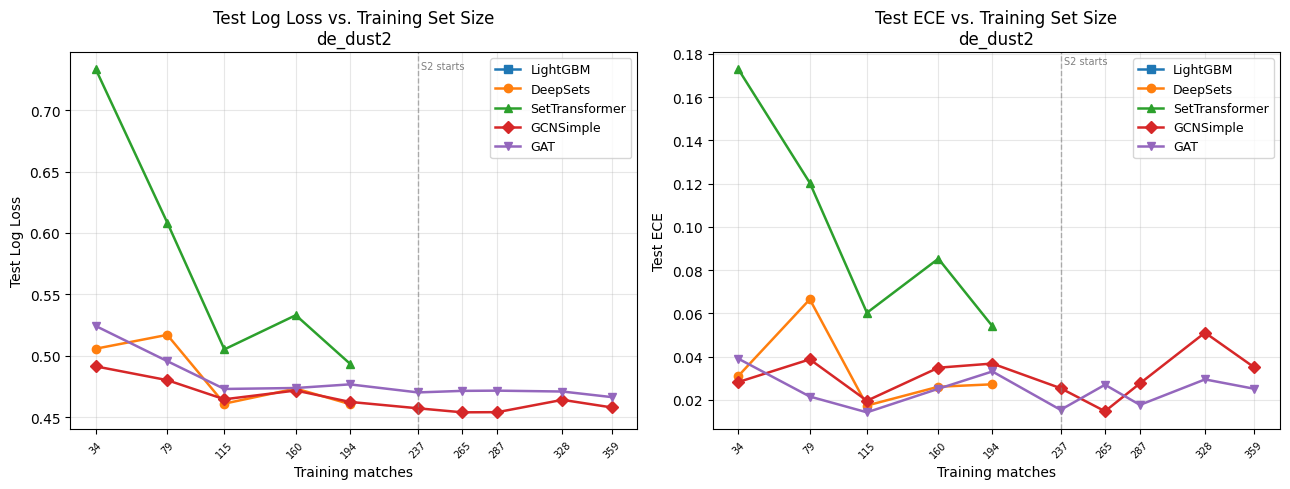

In [20]:
COLORS = {
    'LightGBM':      '#1f77b4',
    'DeepSets':      '#ff7f0e',
    'SetTransformer':'#2ca02c',
    'GCNSimple':     '#d62728',
    'GAT':           '#9467bd',
}
MARKERS = {
    'LightGBM': 's', 'DeepSets': 'o', 'SetTransformer': '^',
    'GCNSimple': 'D', 'GAT': 'v',
}

x_col   = 'n_train_matches'
x_label = 'Training matches'

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for model_name in ['LightGBM', 'DeepSets', 'SetTransformer', 'GCNSimple', 'GAT']:
    sub = results_df[results_df['model'] == model_name].sort_values(x_col)
    axes[0].plot(sub[x_col], sub['test_ll'],  label=model_name,
                 color=COLORS[model_name], marker=MARKERS[model_name],
                 linewidth=1.8, markersize=6)
    axes[1].plot(sub[x_col], sub['test_ece'], label=model_name,
                 color=COLORS[model_name], marker=MARKERS[model_name],
                 linewidth=1.8, markersize=6)

# Annotate S1/S2 boundary
s1_end_matches = results_df.loc[results_df['step'] == len(S1_STEPS) - 1, x_col].iloc[0]
for ax in axes:
    ax.axvline(x=s1_end_matches, color='gray', linestyle='--', linewidth=1, alpha=0.6)
    ax.text(s1_end_matches + 2, ax.get_ylim()[1] * 0.99, 'S2 starts',
            fontsize=7, color='gray', va='top')

x_vals = sorted(results_df[x_col].unique())
step_labels = [label for _, label, _, _ in ABLATION_STEPS]
for ax in axes:
    ax.set_xticks(x_vals)
    ax.set_xticklabels([str(x) for x in x_vals], fontsize=7, rotation=45)
    ax.set_xlabel(x_label)
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel('Test Log Loss')
axes[0].set_title('Test Log Loss vs. Training Set Size\nde_dust2')
axes[0].legend(fontsize=9)

axes[1].set_ylabel('Test ECE')
axes[1].set_title('Test ECE vs. Training Set Size\nde_dust2')
axes[1].legend(fontsize=9)

plt.tight_layout()
fig_path = BASE / 'ablation_training_size_dust2.png'
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
print(f'Figure saved → {fig_path}')
plt.show()

Figure saved → /content/drive/MyDrive/magisterka/ablation_training_size_dust2.png


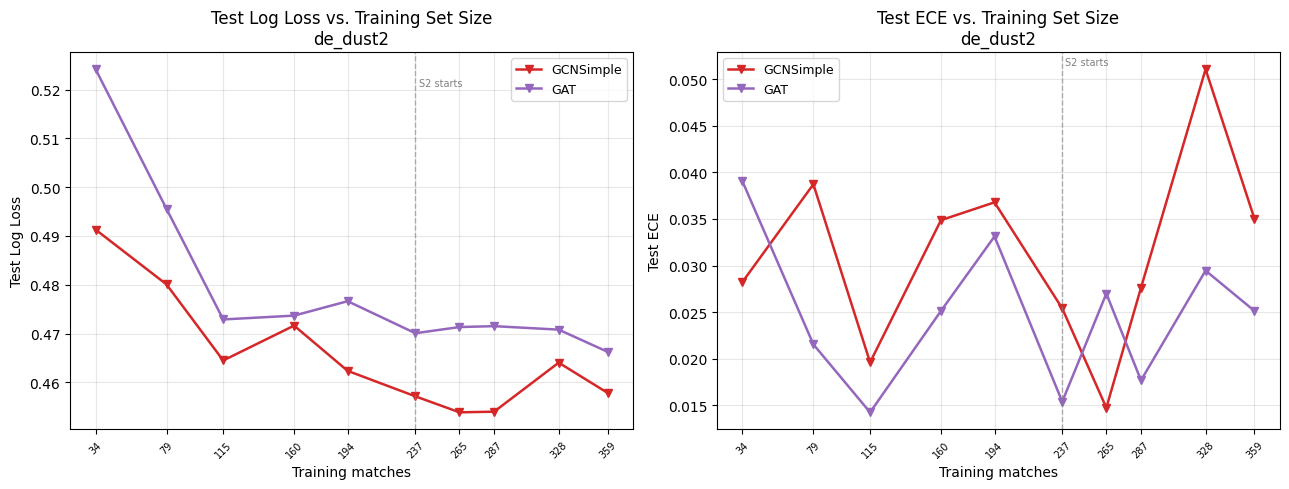

In [22]:
COLORS = {
    'LightGBM':      '#1f77b4',
    'DeepSets':      '#ff7f0e',
    'SetTransformer':'#2ca02c',
    'GCNSimple':     '#d62728',
    'GAT':           '#9467bd',
}
MARKERS = {
    'LightGBM': 's', 'DeepSets': 'o', 'SetTransformer': '^',
    'GCNSimple': 'v', 'GAT': 'v',
}

x_col   = 'n_train_matches'
x_label = 'Training matches'

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for model_name in ['GCNSimple', 'GAT']:
    sub = results_df[results_df['model'] == model_name].sort_values(x_col)
    axes[0].plot(sub[x_col], sub['test_ll'],  label=model_name,
                 color=COLORS[model_name], marker=MARKERS[model_name],
                 linewidth=1.8, markersize=6)
    axes[1].plot(sub[x_col], sub['test_ece'], label=model_name,
                 color=COLORS[model_name], marker=MARKERS[model_name],
                 linewidth=1.8, markersize=6)

# Annotate S1/S2 boundary
s1_end_matches = results_df.loc[results_df['step'] == len(S1_STEPS) - 1, x_col].iloc[0]
for ax in axes:
    ax.axvline(x=s1_end_matches, color='gray', linestyle='--', linewidth=1, alpha=0.6)
    ax.text(s1_end_matches + 2, ax.get_ylim()[1] * 0.99, 'S2 starts',
            fontsize=7, color='gray', va='top')

x_vals = sorted(results_df[x_col].unique())
step_labels = [label for _, label, _, _ in ABLATION_STEPS]
for ax in axes:
    ax.set_xticks(x_vals)
    ax.set_xticklabels([str(x) for x in x_vals], fontsize=7, rotation=45)
    ax.set_xlabel(x_label)
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel('Test Log Loss')
axes[0].set_title('Test Log Loss vs. Training Set Size\nde_dust2')
axes[0].legend(fontsize=9)

axes[1].set_ylabel('Test ECE')
axes[1].set_title('Test ECE vs. Training Set Size\nde_dust2')
axes[1].legend(fontsize=9)

plt.tight_layout()
fig_path = BASE / 'ablation_training_size_dust2.png'
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
print(f'Figure saved → {fig_path}')
plt.show()